# 08. 데이터 시각화 ① matplotlib 활용

**AICE Associate 학습 8단계**

시험에서 시각화는 두 곳에 나옵니다.
1. **데이터 분석 영역**: 분포·관계를 그래프로 확인 (주로 seaborn, 09번에서 학습)
2. **AI 모델링 영역 마지막 문항**: 딥러닝 학습 곡선(loss/accuracy/mse)을 **matplotlib**으로 그리기 ★ 매회 출제

### 학습 목표
1. `plt.plot`, `title`, `xlabel`, `ylabel`, `legend`, `show`의 기본 흐름을 익힌다.
2. 막대·히스토그램·산점도·파이·박스플롯을 그릴 수 있다.
3. `subplots`로 여러 그래프를 한 화면에 배치할 수 있다.
4. 딥러닝 `history` 객체로 학습 곡선을 그릴 수 있다.

In [1]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


---
## 1. 기본 선 그래프

```python
plt.figure(figsize=(가로, 세로))   # (선택) 그림 크기
plt.plot(x, y)                     # 그래프 그리기
plt.title('제목')
plt.xlabel('x축 이름')
plt.ylabel('y축 이름')
plt.legend(['범례1', '범례2'])
plt.show()
```

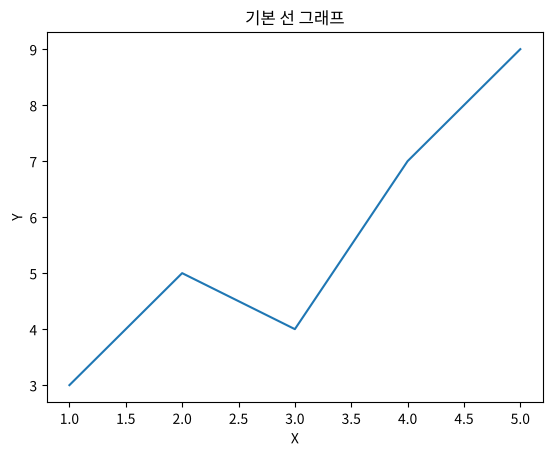

In [2]:
x = [1, 2, 3, 4, 5]
y = [3, 5, 4, 7, 9]

plt.plot(x, y)
plt.title('기본 선 그래프')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

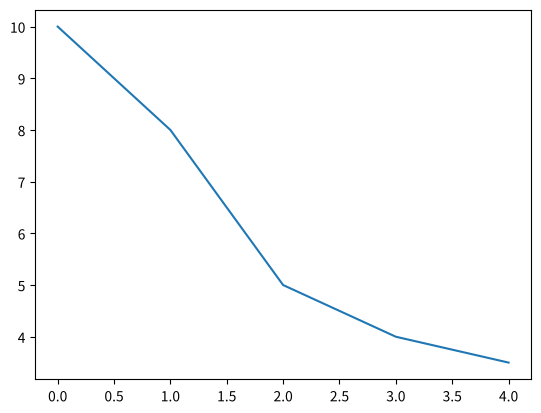

In [3]:
# y값만 주면 x는 0, 1, 2, ... 자동
plt.plot([10, 8, 5, 4, 3.5])
plt.show()

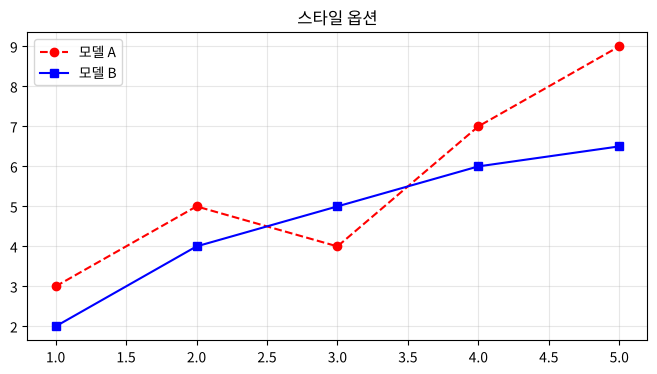

In [4]:
# 스타일 옵션: color, linestyle, marker, linewidth, label
plt.figure(figsize=(8, 4))
plt.plot(x, y, color='red', linestyle='--', marker='o', label='모델 A')
plt.plot(x, [2, 4, 5, 6, 6.5], color='blue', marker='s', label='모델 B')
plt.title('스타일 옵션')
plt.legend()                  # label= 로 지정한 이름이 범례로
plt.grid(True, alpha=0.3)
plt.show()

---
## 2. ★ 딥러닝 학습 곡선 그리기 (시험 마지막 문항 유형)

`model.fit()`이 반환하는 `history` 객체의 `history.history`는 딕셔너리입니다.

```python
history.history = {
    'loss': [...], 'accuracy': [...],            # 학습 데이터 지표
    'val_loss': [...], 'val_accuracy': [...]     # 검증 데이터 지표 (validation_data를 준 경우)
}
```
- 분류: `accuracy`, `val_accuracy`, `loss`, `val_loss`
- 회귀(metrics=['mse']): `mse`, `val_mse`, `loss`, `val_loss`

여기서는 실제 학습 대신 비슷한 구조의 딕셔너리를 만들어 연습합니다. (12번 노트북에서 실제 모델로 다시 그립니다)

In [5]:
class FakeHistory:
    pass

history = FakeHistory()
history.history = {
    'loss':         [0.69, 0.55, 0.47, 0.42, 0.39, 0.37, 0.35, 0.34, 0.33, 0.32],
    'val_loss':     [0.66, 0.53, 0.48, 0.45, 0.44, 0.44, 0.45, 0.46, 0.47, 0.49],
    'accuracy':     [0.60, 0.72, 0.78, 0.81, 0.83, 0.84, 0.85, 0.86, 0.865, 0.87],
    'val_accuracy': [0.63, 0.74, 0.77, 0.79, 0.80, 0.80, 0.795, 0.79, 0.79, 0.785],
}

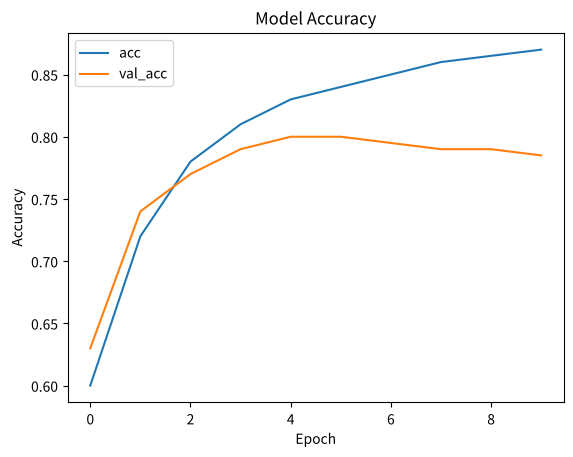

In [6]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['acc', 'val_acc'])
plt.show()

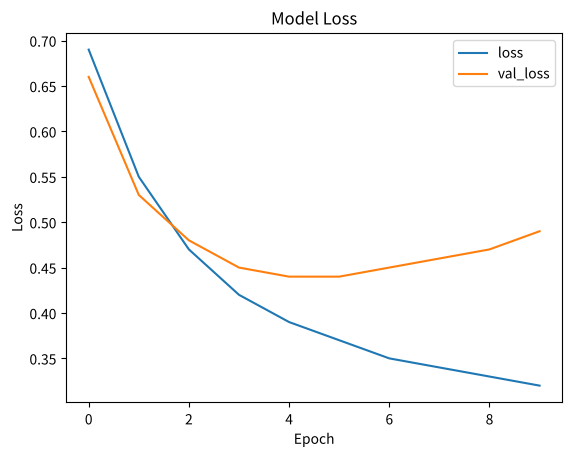

In [7]:
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

> 📈 **그래프 해석**: 학습 loss는 계속 줄지만 **val_loss가 다시 올라가기 시작**하면(여기서는 epoch 5 이후) **과적합(overfitting)** 입니다.
> 이때 `EarlyStopping`이 학습을 멈춰 줍니다.

---
## 3. 여러 종류의 그래프

In [8]:
df = pd.read_csv('titanic.csv')
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


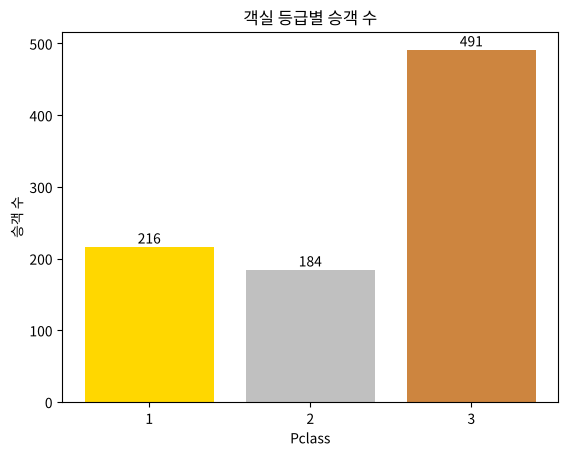

In [9]:
# 막대그래프: bar / barh
cnt = df['Pclass'].value_counts().sort_index()
plt.bar(cnt.index.astype(str), cnt.values, color=['gold', 'silver', 'peru'])
plt.title('객실 등급별 승객 수')
plt.xlabel('Pclass')
plt.ylabel('승객 수')
for i, v in enumerate(cnt.values):
    plt.text(i, v + 5, str(v), ha='center')     # 막대 위에 값 표시
plt.show()

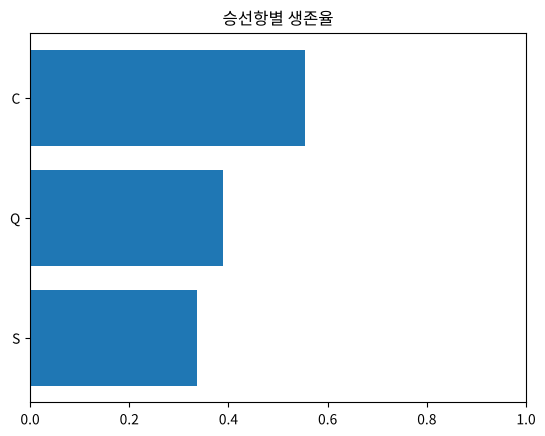

In [10]:
rate = df.groupby('Embarked')['Survived'].mean().sort_values()
plt.barh(rate.index, rate.values)
plt.title('승선항별 생존율')
plt.xlim(0, 1)
plt.show()

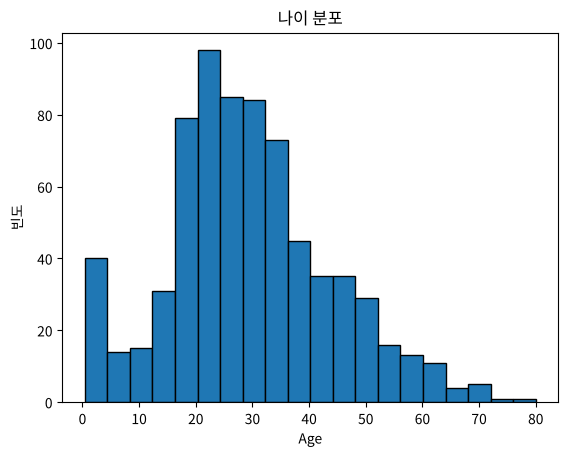

In [11]:
# 히스토그램: 수치형 분포
plt.hist(df['Age'].dropna(), bins=20, edgecolor='black')
plt.title('나이 분포')
plt.xlabel('Age')
plt.ylabel('빈도')
plt.show()

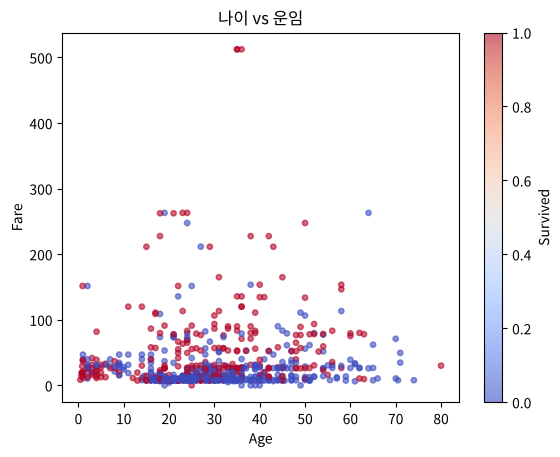

In [12]:
# 산점도: 두 수치형 변수의 관계
plt.scatter(df['Age'], df['Fare'], c=df['Survived'], cmap='coolwarm', alpha=0.6, s=15)
plt.colorbar(label='Survived')
plt.title('나이 vs 운임')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()

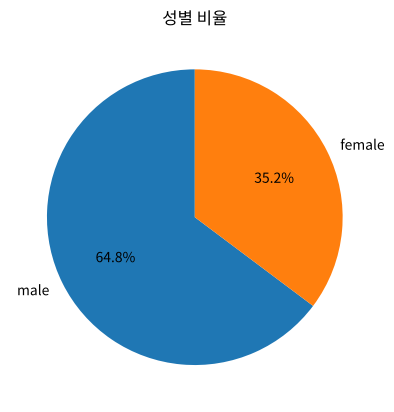

In [13]:
# 파이 차트
sex_cnt = df['Sex'].value_counts()
plt.pie(sex_cnt, labels=sex_cnt.index, autopct='%.1f%%', startangle=90)
plt.title('성별 비율')
plt.show()

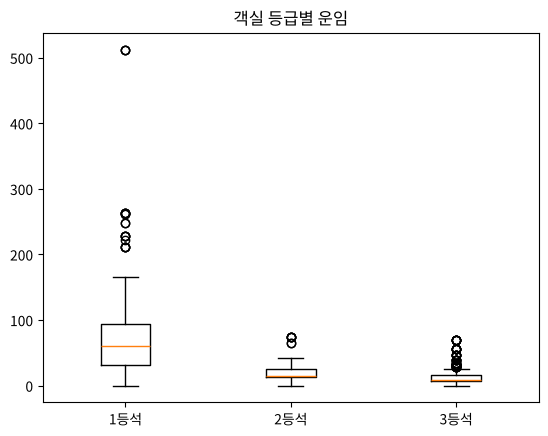

In [14]:
# 박스플롯
plt.boxplot([df.loc[df['Pclass'] == c, 'Fare'] for c in [1, 2, 3]])
plt.xticks([1, 2, 3], ['1등석', '2등석', '3등석'])
plt.title('객실 등급별 운임')
plt.show()

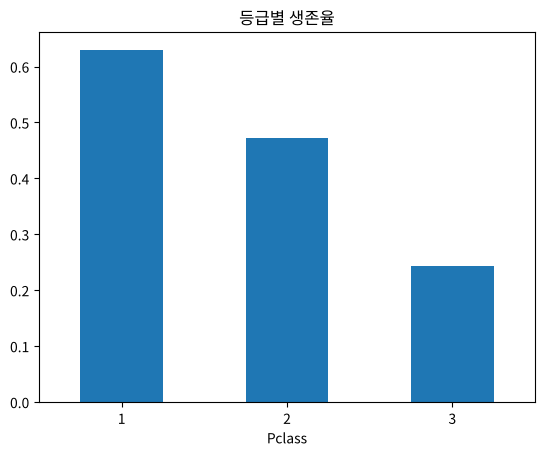

In [15]:
# pandas DataFrame의 plot 메서드 (내부적으로 matplotlib 사용)
df.groupby('Pclass')['Survived'].mean().plot(kind='bar', title='등급별 생존율', rot=0)
plt.show()

---
## 4. ★ 여러 그래프 배치: `subplots`

```python
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
axes[0].plot(...)               # 첫 번째 칸
axes[1].hist(...)               # 두 번째 칸
axes[0].set_title('제목')       # 축(ax)에서는 set_ 접두사!
```
| plt (전체) | ax (개별 칸) |
|---|---|
| `plt.title()` | `ax.set_title()` |
| `plt.xlabel()` | `ax.set_xlabel()` |
| `plt.ylabel()` | `ax.set_ylabel()` |
| `plt.xlim()` | `ax.set_xlim()` |

> 샘플 문항 3번: `plt.< subplots >`, `ax=< axes >[0]`, `axes[0].< set_title >('Wine Count')` 빈칸 채우기가 출제되었습니다.

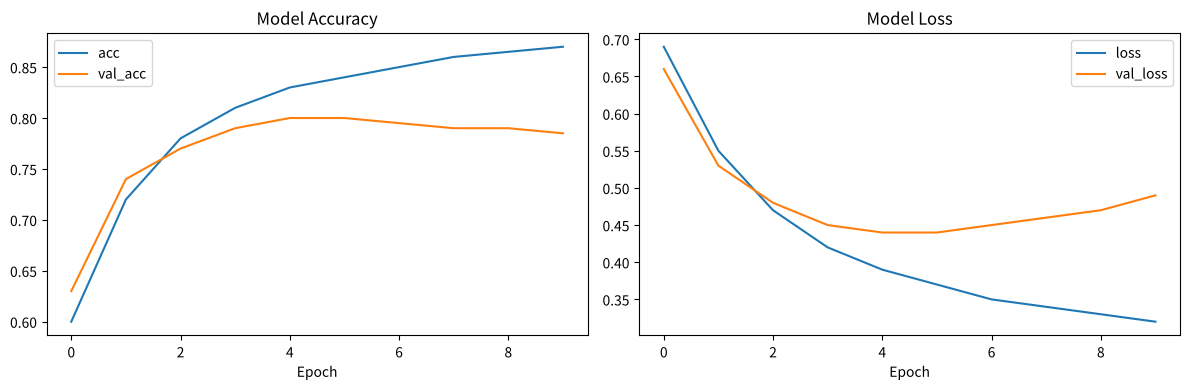

In [16]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'])
axes[0].plot(history.history['val_accuracy'])
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend(['acc', 'val_acc'])

axes[1].plot(history.history['loss'])
axes[1].plot(history.history['val_loss'])
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend(['loss', 'val_loss'])

plt.tight_layout()     # 그래프 간격 자동 조정
plt.show()

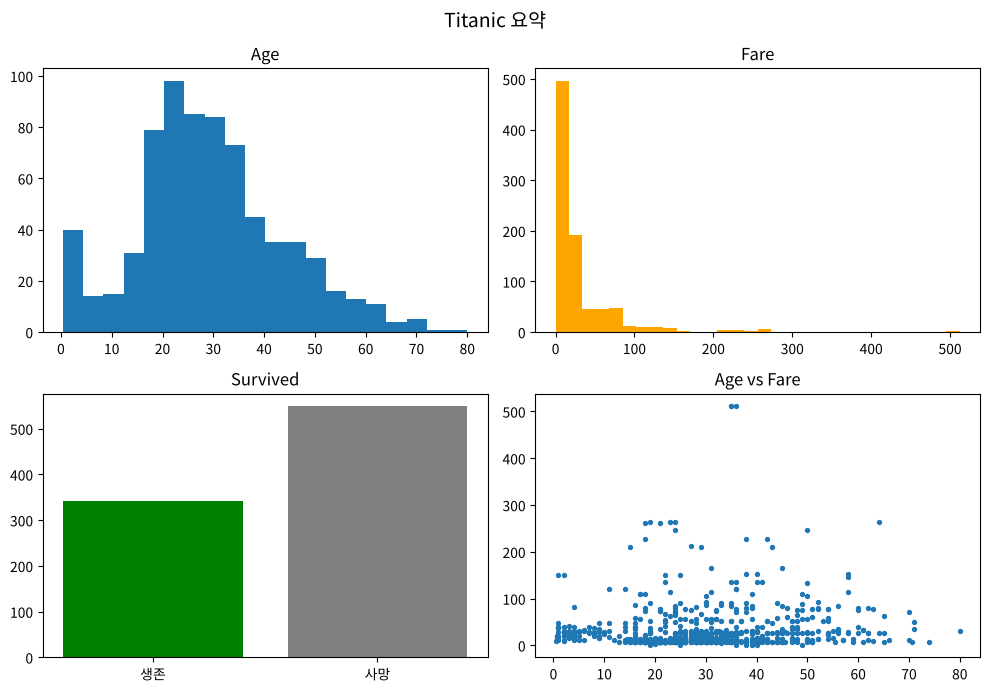

In [17]:
# 2행 2열: axes가 2차원 배열 → axes[행, 열]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].hist(df['Age'].dropna(), bins=20)
axes[0, 0].set_title('Age')
axes[0, 1].hist(df['Fare'], bins=30, color='orange')
axes[0, 1].set_title('Fare')
axes[1, 0].bar(['생존', '사망'], [df['Survived'].sum(), (1 - df['Survived']).sum()], color=['green', 'gray'])
axes[1, 0].set_title('Survived')
axes[1, 1].scatter(df['Age'], df['Fare'], s=8)
axes[1, 1].set_title('Age vs Fare')
plt.suptitle('Titanic 요약', fontsize=14)
plt.tight_layout()
plt.show()

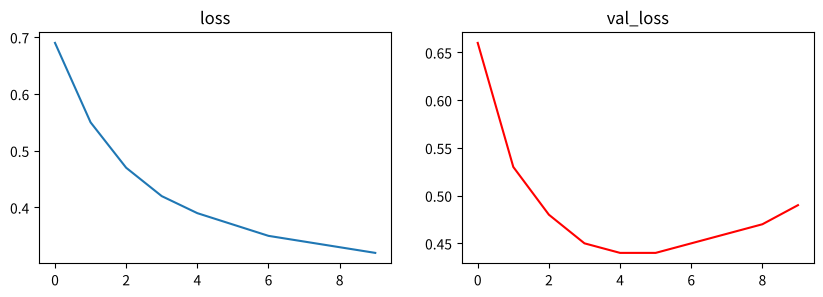

In [18]:
# subplot(행, 열, 번호) 방식도 있습니다
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'])
plt.title('loss')
plt.subplot(1, 2, 2)
plt.plot(history.history['val_loss'], color='red')
plt.title('val_loss')
plt.show()

---
## 5. 기타 유용한 기능

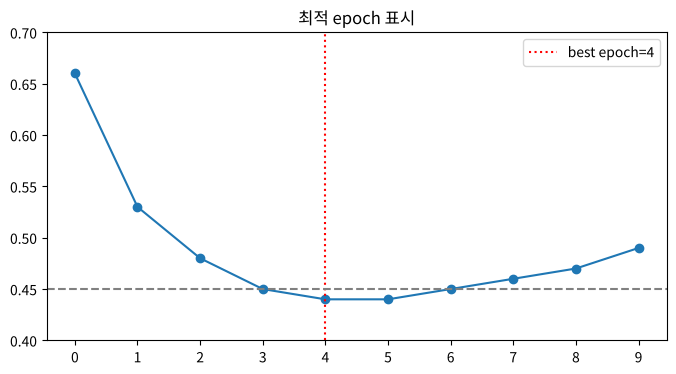

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['val_loss'], marker='o')
best = int(np.argmin(history.history['val_loss']))
plt.axvline(best, color='red', linestyle=':', label=f'best epoch={best}')   # 세로선
plt.axhline(0.45, color='gray', linestyle='--')                            # 가로선
plt.xticks(range(10))
plt.ylim(0.4, 0.7)
plt.legend()
plt.title('최적 epoch 표시')
plt.savefig('val_loss.png', dpi=100)    # 파일로 저장 (show 전에)
plt.show()

---
## ✏️ 연습문제

In [20]:
history2 = FakeHistory()
history2.history = {
    'loss': [5200, 3100, 2200, 1800, 1650, 1580, 1540, 1520],
    'mse':  [5200, 3100, 2200, 1800, 1650, 1580, 1540, 1520],
    'val_loss': [4800, 2900, 2300, 2000, 1900, 1870, 1880, 1890],
    'val_mse':  [4800, 2900, 2300, 2000, 1900, 1870, 1880, 1890],
}

**문제 1.** `history2`를 사용해 학습 MSE와 검증 MSE의 변화를 하나의 그래프로 시각화하세요.
- 범례: `'mse'`, `'val_mse'`
- 제목: `'Model MSE'`, X축: `'Epoch'`, Y축: `'MSE'`

In [21]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 2.** 아래 코드의 빈칸을 채우세요. 빈칸 내용을 `답안2_1`, `답안2_2`에 저장하세요.
```python
plt.plot(< blank2-1 >["loss"])
plt.plot(< blank2-1 >["val_loss"])
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.< blank2-2 >(['loss', 'val_loss'])
plt.show()
```

In [22]:
# 아래 코드의 빈칸을 채우고 실행하세요.

**문제 3.** `subplots`를 이용해 1행 2열 그래프를 그리세요. 왼쪽에는 titanic `Age` 히스토그램(제목 `'Age'`), 오른쪽에는 `Sex`별 승객 수 막대그래프(제목 `'Sex'`)를 그리세요.

In [23]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 4.** 아래 코드의 오류를 정정하세요.
```python
fig, axes = plt.subplot(1, 2, figsize=(10, 4))
axes[0].plot(history2.history['loss'])
axes[0].title('loss')
axes[1].plot(history2.history['val_loss'])
axes[1].title('val_loss')
plt.show()
```

In [24]:
# 아래의 코드를 정정하고 실행하세요.

---
## ✅ 정답 및 해설

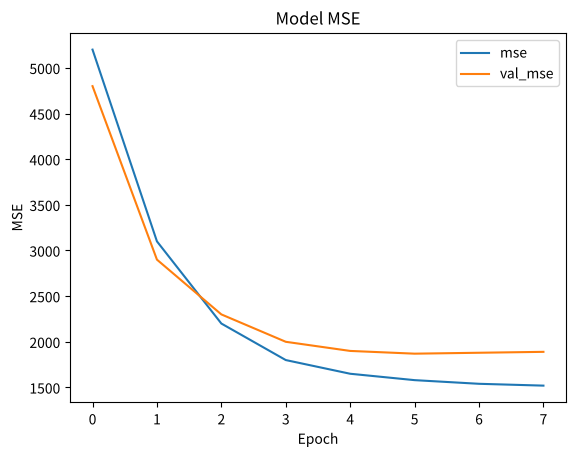

In [25]:
# 문제 1
plt.plot(history2.history['mse'])
plt.plot(history2.history['val_mse'])
plt.title('Model MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend(['mse', 'val_mse'])
plt.show()

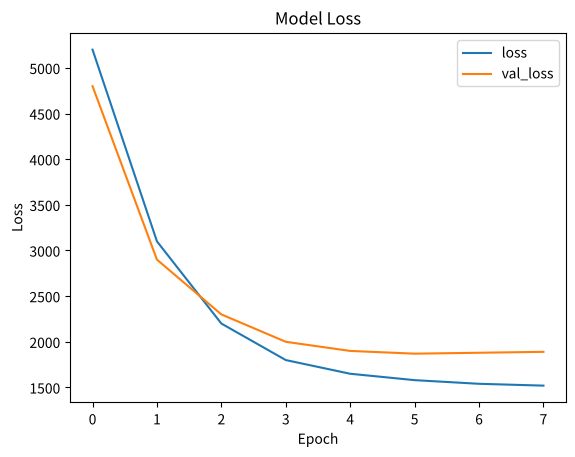

In [26]:
# 문제 2
plt.plot(history2.history["loss"])
plt.plot(history2.history["val_loss"])
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(['loss', 'val_loss'])
plt.show()
답안2_1 = 'history2.history'
답안2_2 = 'legend'

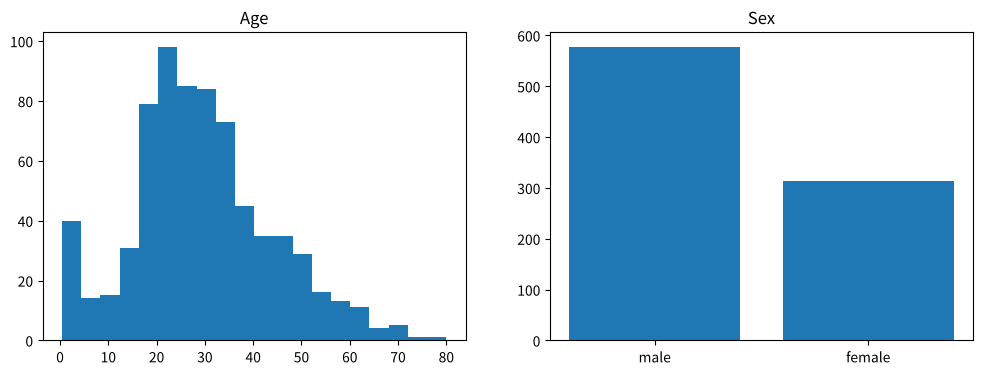

In [27]:
# 문제 3
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
axes[0].hist(df['Age'].dropna(), bins=20)
axes[0].set_title('Age')
sex_cnt = df['Sex'].value_counts()
axes[1].bar(sex_cnt.index, sex_cnt.values)
axes[1].set_title('Sex')
plt.show()

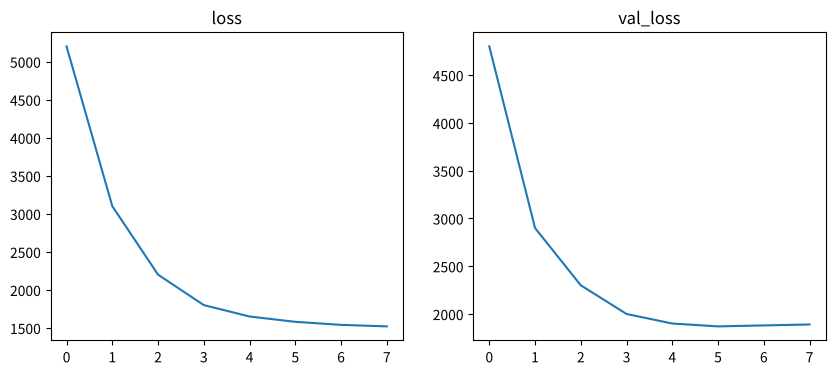

In [28]:
# 문제 4 : subplot -> subplots, ax에서는 title -> set_title
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history2.history['loss'])
axes[0].set_title('loss')
axes[1].plot(history2.history['val_loss'])
axes[1].set_title('val_loss')
plt.show()